# Gasto público en prestaciones que no son pensiones ni sanidad

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "gasto-prestaciones-no-pensiones"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Gasto público en prestaciones que no son pensiones ni sanidad"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del PIB"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Lo que gastan las administraciones públicas en las prestaciones sociales que no son ni pensiones de jubilación y supervivencia ni sanidad, en porcentaje del PIB: las de **incapacidad** (pensiones de incapacidad permanente y atención a la discapacidad; en la OCDE, también las bajas por enfermedad), **familia e hijos**, **desempleo**, **vivienda** y **exclusión social** (rentas mínimas como el ingreso mínimo vital y otras ayudas). Completa `gasto-pensiones-pib`: es lo que el sistema dedica a quienes no están jubilados.

**Cómo se lee.** Un valor de 7 significa que esas prestaciones costaron el equivalente al 7 % del PIB ese año. El gasto en desempleo sube en las recesiones aunque no cambien las reglas, porque hay más parados.

**Limitaciones.**
- Suma prestaciones en dinero y en especie (por ejemplo, plazas de residencia o escuelas infantiles), que cada país organiza de forma distinta.
- Las fuentes no coinciden del todo: la OCDE (SOCX) cuenta en incapacidad las bajas por enfermedad, que Eurostat (ESSPROS) cuenta junto a la sanidad (y por eso aquí no se suman), e incluye en familia la educación infantil de 0 a 3 años; ESSPROS incluye algún gasto privado obligatorio. SOCX cuenta aparte las políticas activas de empleo, que aquí no se suman. La sección 3 compara España en las dos.
- La incapacidad incluye las pensiones de incapacidad permanente, que en algunos países son una vía de salida del mercado de trabajo antes de la jubilación.

## 2. Descarga

- **España y UE-27:** Eurostat, gasto en prestaciones sociales por función (`spr_exp_func`, ESSPROS, `SPR`), en % del PIB: incapacidad (`DIS`), familia e hijos (`FAM`), desempleo (`UNE`), vivienda (`HOU`) y exclusión social (`EXCL`).
- **OCDE, EE. UU. y Canadá:** OCDE, base de gasto social (SOCX, `OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0`), gasto público (`ES10`), en dinero y en especie (`_T`), en % del PIB: incapacidad (`TP31`), familia (`TP51`), desempleo (`TP71`), vivienda (`TP82`) y otras áreas de la política social (`TP91`). También España, para compararla con Eurostat.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, oecd
from lib.tipos import FuenteMeta

FUNCIONES = {"DIS": "incapacidad", "FAM": "familia e hijos", "UNE": "desempleo", "HOU": "vivienda", "EXCL": "exclusión social"}
ess = {}
for f_ in FUNCIONES:
    ess[f_], fu = eurostat.get(
        "spr_exp_func", {"freq": "A", "spdeps": "SPR", "spfunc": f_, "unit": "PC_GDP"}, desde=DESDE
    )
    if f_ == "DIS":
        fuentes_ess = fu

# SOCX: REF_AREA.FREQ.MEASURE.UNIT_MEASURE.EXPEND_SOURCE.SPENDING_TYPE.PROGRAMME_TYPE.PRICE_BASE
DATAFLOW_SOCX = "OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0"
PROGRAMAS = {"TP31": "incapacidad", "TP51": "familia", "TP71": "desempleo", "TP82": "vivienda", "TP91": "otras áreas"}
AREAS = {"OECD": "ocde", "USA": "eeuu", "CAN": "canada", "ESP": "espana_socx"}
socx = {}
for p_ in PROGRAMAS:
    socx[p_], fuentes_socx = oecd.get(DATAFLOW_SOCX, f"{{AREA}}.A.SOCX.PT_B1GQ.ES10._T.{p_}._Z", areas=AREAS, desde=DESDE)

## 3. Transformación

- **España y UE-27:** suma de las cinco funciones de ESSPROS, solo en los años con las cinco.
- **OCDE, EE. UU. y Canadá:** suma de los cinco programas de SOCX, solo en los años con los cinco.
- Se guarda en el notebook el desglose por función y se compara España en las dos fuentes.

In [ ]:
def suma(partes, geo):
    t = pd.concat({k: d[d["serie"] == geo].set_index("periodo")["valor"] for k, d in partes.items()}, axis=1)
    return t.dropna().sum(axis=1), t


filas, desglose = [], {}
for g in ("espana", "ue27"):
    s, desglose[g] = suma(ess, g)
    filas.append(pd.DataFrame({"serie": g, "periodo": s.index, "valor": s.values}))
for g in ("ocde", "eeuu", "canada", "espana_socx"):
    s, desglose[g] = suma(socx, g)
    if g != "espana_socx":
        filas.append(pd.DataFrame({"serie": g, "periodo": s.index, "valor": s.values}))
df = pd.concat(filas, ignore_index=True)
assert df["valor"].between(0.5, 25).all(), "gasto fuera de rango: ¿unidades?"

HOY = fuentes_ess[0].fecha_consulta
fuentes = [
    FuenteMeta(g, eurostat.ORGANISMO, "spr_exp_func (spdeps=SPR, spfunc=DIS+FAM+UNE+HOU+EXCL, unit=PC_GDP)",
               fuentes_ess[0].url, HOY) for g in ("espana", "ue27")
] + [
    FuenteMeta(g, oecd.ORGANISMO, "DSD_SOCX_AGG@DF_SOCX_AGG (TP31+TP51+TP71+TP82+TP91, ES10, _T, PT_B1GQ)",
               oecd.URL_EXPLORER, HOY) for g in ("ocde", "eeuu", "canada")
]

print("Desglose por función, España (Eurostat), últimos años:")
display(desglose["espana"].round(2).tail(6))
print("Desglose por programa, España (SOCX), últimos años:")
display(desglose["espana_socx"].round(2).tail(6))

serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]
comp = pd.DataFrame({"Eurostat": desglose["espana"].dropna().sum(axis=1), "SOCX": desglose["espana_socx"].dropna().sum(axis=1)}).dropna()
comp["SOCX − Eurostat"] = comp["SOCX"] - comp["Eurostat"]
display(comp.round(2).iloc[::3])
COMUN = (int(comp.index.min()), int(comp.index.max()))
DIF_MIN, DIF_MAX = comp["SOCX − Eurostat"].min(), comp["SOCX − Eurostat"].max()

Desglose por función, España (Eurostat), últimos años:


,DIS,FAM,UNE,HOU,EXCL
periodo,,,,,
2020,1.80,1.58,3.58,0.13,0.33
2021,1.70,1.53,2.54,0.13,0.44
2022,1.60,1.46,1.65,0.12,0.46
2023,1.58,1.39,1.57,0.12,0.48
2024,1.52,1.43,1.53,0.12,0.51
2025,1.48,1.37,1.50,0.11,0.53


Desglose por programa, España (SOCX), últimos años:


,TP31,TP51,TP71,TP82,TP91
periodo,,,,,
2016,2.39,1.20,1.77,0.10,0.20
2017,2.39,1.22,1.55,0.10,0.20
2018,2.35,1.23,1.49,0.11,0.20
2019,2.53,1.28,1.52,0.11,0.21
2020,3.07,1.52,3.37,0.13,0.29
2021,2.90,1.48,2.35,0.13,0.40


,Eurostat,SOCX,SOCX − Eurostat
periodo,,,
1995,5.58,6.23,0.65
1998,4.90,5.67,0.77
2001,4.71,5.03,0.32
2004,4.97,5.45,0.48
2007,5.14,5.65,0.51
2010,6.88,7.33,0.45
2013,6.84,7.14,0.30
2016,5.17,5.66,0.50
2019,5.00,5.64,0.64


### Notas

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


es_ult = desglose["espana"].dropna()
ULT = int(es_ult.index.max())
partes_ult = ", ".join(f"{FUNCIONES[k]} {fmt(es_ult.loc[ULT, k])}" for k in FUNCIONES)
NOTAS = [
    "España y UE-27: Eurostat, gasto en prestaciones de protección social por función (spr_exp_func, ESSPROS), suma "
    "de incapacidad, familia e hijos, desempleo, vivienda y exclusión social, en % del PIB. Media UE-27 de "
    "composición actual (EU27_2020).",
    "OCDE, EE. UU. y Canadá: OCDE, base de gasto social (SOCX), gasto público en dinero y en especie, suma de los "
    "programas de incapacidad, familia, desempleo, vivienda y otras áreas de la política social, en % del PIB; sin "
    "las políticas activas de empleo (TP60).",
    f"España en las dos fuentes: de {COMUN[0]} a {COMUN[1]}, la suma de SOCX difiere de la de Eurostat entre "
    f"{fmt(DIF_MIN)} y {fmt(DIF_MAX)} puntos del PIB, sobre todo porque SOCX cuenta en incapacidad las bajas por "
    f"enfermedad, que ESSPROS cuenta en la función de enfermedad y atención sanitaria (que aquí no se suma); además, "
    f"SOCX incluye en familia la educación infantil de 0 a 3 años y ESSPROS, algún gasto privado obligatorio.",
    f"Desglose de España en {ULT} (Eurostat, % del PIB): {partes_ult}.",
    "La incapacidad incluye las pensiones de incapacidad permanente en las dos fuentes, y las prestaciones por "
    "incapacidad temporal (bajas por enfermedad) solo en SOCX (OCDE, EE. UU. y Canadá). El gasto en desempleo sube en "
    "las recesiones porque hay más parados.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat, gasto en prestaciones de protección social por función (spr_exp_func, ESSPROS), suma de incapacidad, familia e hijos, desempleo, vivienda y exclusión social, en % del PIB. Media UE-27 de composición actual (EU27_2020).
- OCDE, EE. UU. y Canadá: OCDE, base de gasto social (SOCX), gasto público en dinero y en especie, suma de los programas de incapacidad, familia, desempleo, vivienda y otras áreas de la política social, en % del PIB; sin las políticas activas de empleo (TP60).
- España en las dos fuentes: de 1995 a 2021, la suma de SOCX difiere de la de Eurostat entre 0,3 y 1,0 puntos del PIB, sobre todo porque SOCX cuenta en incapacidad las bajas por enfermedad, que ESSPROS cuenta en la función de enfermedad y atención sanitaria (que aquí no se suma); además, SOCX incluye en familia la educación infantil de 0 a 3 años y ESSPROS, algún gasto privado obligatorio.
- Desglose de España en 2025 (Eurostat, % del PIB): incapacidad 1,5, familia e hijos 1,4, desempleo

## 4. Visualización

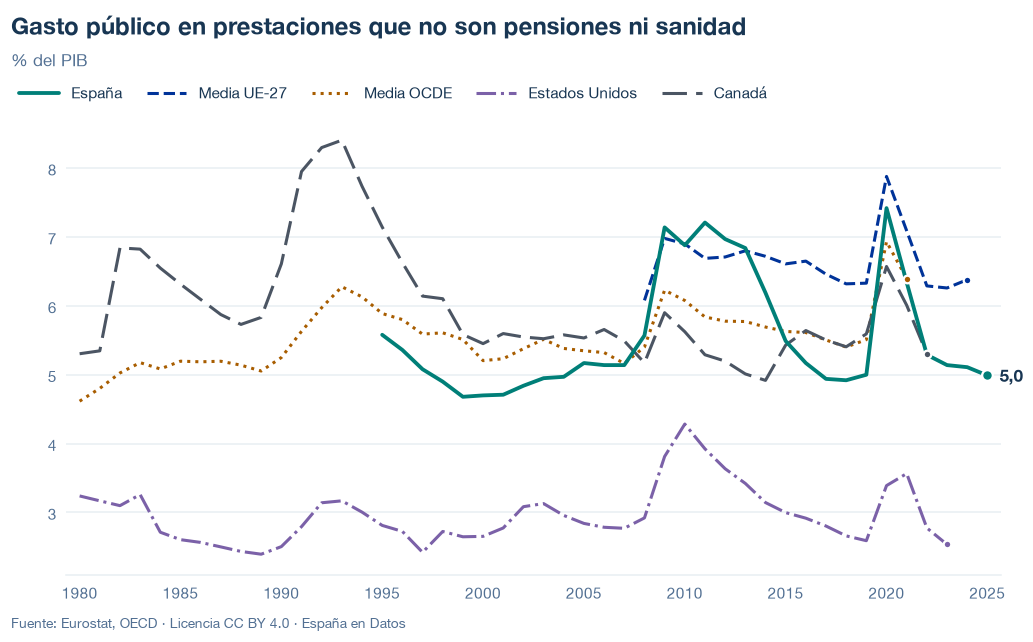

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/gasto-prestaciones-no-pensiones.json y data/gasto-prestaciones-no-pensiones.csv


## 6. Fuentes, notas y licencia

- Eurostat, `spr_exp_func` (`SPR`; `DIS`, `FAM`, `UNE`, `HOU`, `EXCL`; `PC_GDP`): España y UE-27.
- OCDE, SOCX (`OECD.ELS.SPD,DSD_SOCX_AGG@DF_SOCX_AGG,1.0`; `TP31`, `TP51`, `TP71`, `TP82`, `TP91`; `ES10`, `_T`, `PT_B1GQ`): OCDE, EE. UU., Canadá y, para comparar, España.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.